
# Modelos de pronóstico para series de tiempo

Una **serie de tiempo** es una secuencia de datos ordenados en el tiempo, recolectados en intervalos regulares (como cada hora, día, mes o año). Su característica fundamental es que el orden temporal es crucial, ya que las observaciones suelen estar correlacionadas con sus valores pasados (dependencia temporal).

## Diferencias entre modelos de pronóstico y modelos de regresión convencionales:

La diferencia principal radica en la **estructura de los datos y la naturaleza de la relación entre las variables**.

| Característica | Modelos de Regresión Convencionales | Modelos de Pronóstico de Series de Tiempo |
| :--- | :--- | :--- |
| **Supuesto Central** | Las observaciones son **independientes** entre sí. | Las observaciones son **dependientes** (autocorrelación). El valor pasado influye en el futuro. |
| **Relación con el Tiempo** | El tiempo suele ser irrelevante o es solo una variable explicativa más (ej: `edad`). | El tiempo es la **dimensión fundamental**. El objetivo es modelar explícitamente la estructura temporal. |
| **Variables de Entrada** | Usa variables predictoras independientes (ej: `tamaño`, `ingresos`) para predecir una variable objetivo. | Usa principalmente el **historial de la propia serie** (valores rezagados, tendencia, estacionalidad) como predictores. |
| **Propósito** | Explicar o predecir una variable en función de **otras** variables. | Predecir valores **futuros** de la misma variable, extrapolando su patrón histórico. |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT_DIR = Path().resolve().parent
DATA_DIR = ROOT_DIR / "data/raw"

In [2]:
file_name = "1.1.1.TCM_Serie histórica IQY.xlsx"
file_path = DATA_DIR / file_name

trm = pd.read_excel(file_path, header=7 )
trm.drop(trm.tail(4).index, axis=0, inplace=True)
trm.rename({trm.columns[0]:'Fecha', trm.columns[1]:'TRM'}, axis=1, inplace=True)
trm['Fecha'] = pd.to_datetime(trm['Fecha'], dayfirst=True)
trm.set_index('Fecha', inplace=True)
trm = trm.asfreq('B')
trm

,TRM
Fecha,
1991-11-27,693.32
1991-11-28,693.99
1991-11-29,694.70
1991-12-02,643.42
1991-12-03,639.22
...,...
2024-03-07,3932.55
2024-03-08,3920.79
2024-03-11,3905.45


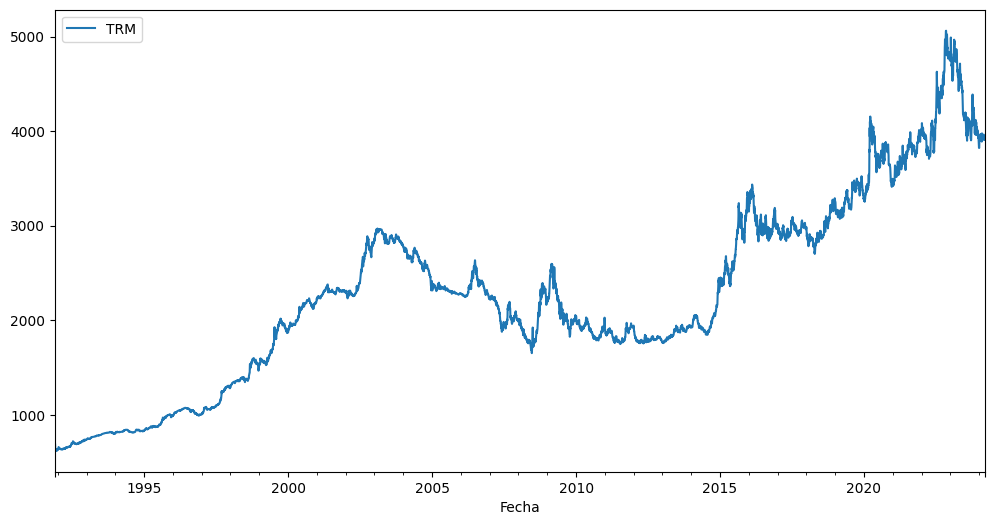

In [3]:
trm.plot(figsize=(12, 6));

## Feature extraction


Vamos a empezar creando nuevas características con los retardos, que son los valores que toma la serie en los periodos anteriores.

In [4]:
retardo = 30
for i in range(1, retardo+1):
    trm['TRM-'+str(i)] = trm['TRM'].shift(i)
trm.dropna(inplace=True)
trm.head()

,TRM,TRM-1,TRM-2,TRM-3,TRM-4,TRM-5,TRM-6,TRM-7,TRM-8,TRM-9,...,TRM-21,TRM-22,TRM-23,TRM-24,TRM-25,TRM-26,TRM-27,TRM-28,TRM-29,TRM-30
Fecha,,,,,,,,,,,,,,,,,,,,,
1992-01-08,638.17,638.07,638.07,632.58,638.61,632.37,632.37,632.37,631.63,622.95,...,622.92,638.06,627.16,631.51,635.70,639.22,643.42,694.70,693.99,693.32
1992-01-09,638.61,638.17,638.07,638.07,632.58,638.61,632.37,632.37,632.37,631.63,...,627.46,622.92,638.06,627.16,631.51,635.70,639.22,643.42,694.70,693.99
1992-01-10,637.86,638.61,638.17,638.07,638.07,632.58,638.61,632.37,632.37,632.37,...,633.09,627.46,622.92,638.06,627.16,631.51,635.70,639.22,643.42,694.70
1992-01-13,645.04,637.86,638.61,638.17,638.07,638.07,632.58,638.61,632.37,632.37,...,632.35,633.09,627.46,622.92,638.06,627.16,631.51,635.70,639.22,643.42
1992-01-14,659.74,645.04,637.86,638.61,638.17,638.07,638.07,632.58,638.61,632.37,...,630.91,632.35,633.09,627.46,622.92,638.06,627.16,631.51,635.70,639.22


También se suele usar como características las medias móviles, que son los promedios de los últimos k periodos. En este caso vamos a calcular la media móvil de los últimos 7 días:

In [5]:
trm['rolling_7d_mean'] = trm['TRM'].shift(1).rolling(7).mean()
trm.dropna(inplace=True)
trm

,TRM,TRM-1,TRM-2,TRM-3,TRM-4,TRM-5,TRM-6,TRM-7,TRM-8,TRM-9,...,TRM-22,TRM-23,TRM-24,TRM-25,TRM-26,TRM-27,TRM-28,TRM-29,TRM-30,rolling_7d_mean
Fecha,,,,,,,,,,,,,,,,,,,,,
1992-01-17,652.91,653.45,657.49,659.74,645.04,637.86,638.61,638.17,638.07,638.07,...,626.52,626.23,630.91,632.35,633.09,627.46,622.92,638.06,627.16,647.194286
1992-01-20,645.35,652.91,653.45,657.49,659.74,645.04,637.86,638.61,638.17,638.07,...,633.35,626.52,626.23,630.91,632.35,633.09,627.46,622.92,638.06,649.300000
1992-01-21,645.97,645.35,652.91,653.45,657.49,659.74,645.04,637.86,638.61,638.17,...,621.71,633.35,626.52,626.23,630.91,632.35,633.09,627.46,622.92,650.262857
1992-01-22,647.04,645.97,645.35,652.91,653.45,657.49,659.74,645.04,637.86,638.61,...,620.62,621.71,633.35,626.52,626.23,630.91,632.35,633.09,627.46,651.421429
1992-01-23,647.01,647.04,645.97,645.35,652.91,653.45,657.49,659.74,645.04,637.86,...,622.95,620.62,621.71,633.35,626.52,626.23,630.91,632.35,633.09,651.707143
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-03-07,3932.55,3945.32,3948.67,3934.82,3931.31,3933.56,3935.59,3963.08,3949.36,3935.64,...,3975.74,3928.11,3889.05,3915.56,3925.60,3918.93,3925.26,3932.96,3929.95,3941.764286
2024-03-08,3920.79,3932.55,3945.32,3948.67,3934.82,3931.31,3933.56,3935.59,3963.08,3949.36,...,3950.57,3975.74,3928.11,3889.05,3915.56,3925.60,3918.93,3925.26,3932.96,3937.402857
2024-03-11,3905.45,3920.79,3932.55,3945.32,3948.67,3934.82,3931.31,3933.56,3935.59,3963.08,...,3962.23,3950.57,3975.74,3928.11,3889.05,3915.56,3925.60,3918.93,3925.26,3935.288571


Finalmente vamos a añadir otras características que pueden ser importantes, como el día de la semana, el mes del año y el año:

In [6]:
trm['dia_semana'] = trm.index.weekday
trm['mes'] = trm.index.month
trm['año'] = trm.index.year
trm.head()

,TRM,TRM-1,TRM-2,TRM-3,TRM-4,TRM-5,TRM-6,TRM-7,TRM-8,TRM-9,...,TRM-25,TRM-26,TRM-27,TRM-28,TRM-29,TRM-30,rolling_7d_mean,dia_semana,mes,año
Fecha,,,,,,,,,,,,,,,,,,,,,
1992-01-17,652.91,653.45,657.49,659.74,645.04,637.86,638.61,638.17,638.07,638.07,...,632.35,633.09,627.46,622.92,638.06,627.16,647.194286,4,1,1992
1992-01-20,645.35,652.91,653.45,657.49,659.74,645.04,637.86,638.61,638.17,638.07,...,630.91,632.35,633.09,627.46,622.92,638.06,649.300000,0,1,1992
1992-01-21,645.97,645.35,652.91,653.45,657.49,659.74,645.04,637.86,638.61,638.17,...,626.23,630.91,632.35,633.09,627.46,622.92,650.262857,1,1,1992
1992-01-22,647.04,645.97,645.35,652.91,653.45,657.49,659.74,645.04,637.86,638.61,...,626.52,626.23,630.91,632.35,633.09,627.46,651.421429,2,1,1992
1992-01-23,647.01,647.04,645.97,645.35,652.91,653.45,657.49,659.74,645.04,637.86,...,633.35,626.52,626.23,630.91,632.35,633.09,651.707143,3,1,1992


## Modelado


Ahora ya podemos obtener la matriz de características y el vector objetivo.

Además, ya podemos partir los datos en subconjuntos de entrenamiento y prueba, pero en este caso la partición no se hace de manera aleatoria, porque no tendría sentido hacer predicciones usando datos futuros. Por esta razón, dependiendo del **horizonte** de predicción, es decir, de cuánto tiempo hacia adelante se quieren hacer predicciones, se tomas los datos "más antiguos" para entrenamiento, y los más "nuevos" para prueba.

Entrenamiento: 1992-01-17 a 2023-12-20 (8329 registros)
Prueba:        2023-12-21 a 2024-03-13 (60 registros)


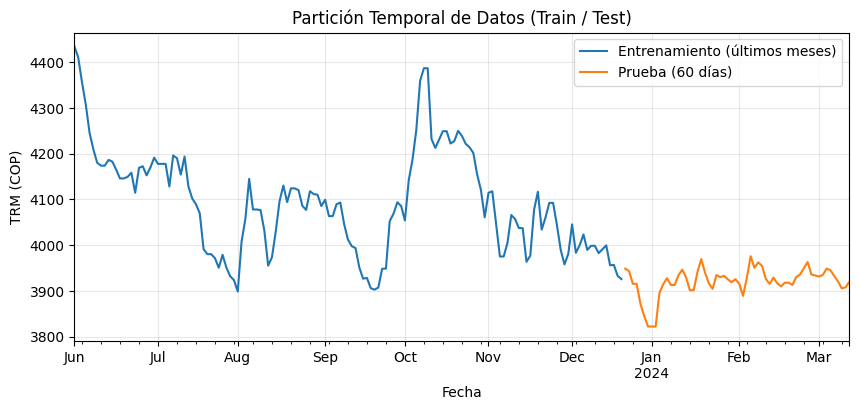

In [7]:
X = trm.drop(['TRM'], axis=1)
y = trm['TRM']

# Partición temporal: 60 días hábiles para prueba (~3 meses)
test_size = 60
X_train = X.iloc[:-test_size]
X_test = X.iloc[-test_size:]
y_train = y.iloc[:-test_size]
y_test = y.iloc[-test_size:]

print(f"Entrenamiento: {y_train.index[0].date()} a {y_train.index[-1].date()} ({len(y_train)} registros)")
print(f"Prueba:        {y_test.index[0].date()} a {y_test.index[-1].date()} ({len(y_test)} registros)")

# Graficación de la partición (segundo semestre de 2023 y periodo de prueba 2024)
plt.figure(figsize=(10, 4))
y_train.loc['2023-06':].plot(label='Entrenamiento (últimos meses)', color='tab:blue')
y_test.plot(label='Prueba (60 días)', color='tab:orange')
plt.title('Partición Temporal de Datos (Train / Test)')
plt.ylabel('TRM (COP)')
plt.legend()
plt.grid(True, alpha=0.3);

Un primer modelo que se podría implementar como modelo base, es el llamado modelo ingenueo (*naive*), en el cual el pronóstico es simplemente el dato del día anterior:

In [8]:
from sklearn.metrics import mean_absolute_percentage_error, root_mean_squared_error

y_naive_test = X_test['TRM-1']

rmse_naive = root_mean_squared_error(y_test, y_naive_test)
mape_naive = mean_absolute_percentage_error(y_test, y_naive_test)

print(f"Naive RMSE: {rmse_naive:.4f} | MAPE: {mape_naive:.4f}")

Naive RMSE: 21.0322 | MAPE: 0.0040


Ahora vamos a entrenar un modelo de árbol de decisión, por facilidad, con la intención de superar el desempeño del modelo ingenuo:

In [9]:
from sklearn.metrics import mean_absolute_percentage_error, root_mean_squared_error
from sklearn.tree import DecisionTreeRegressor

model = DecisionTreeRegressor(random_state=1)
model.fit(X_train, y_train)

# Predicción del modelo
y_pred_dt = model.predict(X_test)

# Línea base Naive (persistencia del día anterior)
y_naive = X_test['TRM-1']

# Métricas comparativas
rmse_naive = root_mean_squared_error(y_test, y_naive)
mape_naive = mean_absolute_percentage_error(y_test, y_naive)
rmse_dt = root_mean_squared_error(y_test, y_pred_dt)
mape_dt = mean_absolute_percentage_error(y_test, y_pred_dt)

print(f"Naive (y_t-1)  | RMSE: {rmse_naive:6.2f} | MAPE: {mape_naive*100:.2f}%")
print(f"Árbol CART     | RMSE: {rmse_dt:6.2f} | MAPE: {mape_dt*100:.2f}%")

Naive (y_t-1)  | RMSE:  21.03 | MAPE: 0.40%
Árbol CART     | RMSE:  41.96 | MAPE: 0.84%


Vemos que un árbol sin podar no mejora el desempeño de un modelo ingenuo.

En la gráfica de abajo se observan los pronósticos versus los datos reales:

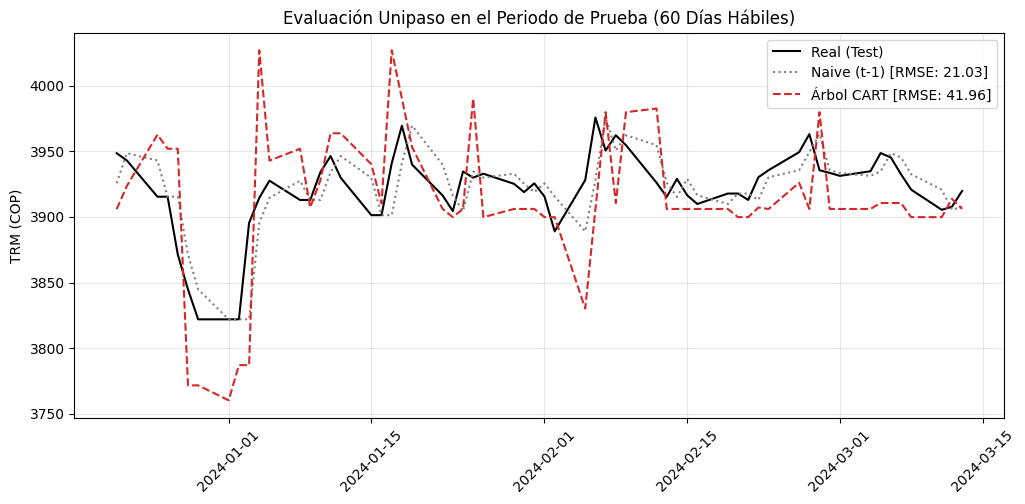

In [10]:
plt.figure(figsize=(12, 5))
plt.plot(y_test.index, y_test, label='Real (Test)', color='black', linewidth=1.5)
plt.plot(y_test.index, y_naive, label=f'Naive (t-1) [RMSE: {rmse_naive:.2f}]', linestyle=':', color='gray')
plt.plot(y_test.index, y_pred_dt, label=f'Árbol CART [RMSE: {rmse_dt:.2f}]', linestyle='--', color='tab:red')
plt.title('Evaluación Unipaso en el Periodo de Prueba (60 Días Hábiles)')
plt.ylabel('TRM (COP)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3);

Los coeficientes de este modelo son:

In [11]:
trm_features = pd.DataFrame({
    'Feature': X_train.columns, 
    'Coeficientes': model.feature_importances_
    })
trm_features.sort_values('Coeficientes', ascending=False).head(5)

,Feature,Coeficientes
0,TRM-1,0.818424
4,TRM-5,0.179246
15,TRM-16,0.001913
8,TRM-9,0.000057
9,TRM-10,0.000028


Obsérvese como la variable **TRM-1** absorbe el $81.84%$ del peso de la predicción.

## Sintonización de hiperparámetros

Para sintonizar hiperparámetros por validación cruzada debemos cuidarnos nuevamente de usar datos futuros para hacer predicciones, así que no se puede usar el método estándar de partición en folds. En vez de esto se recomienda usar el método `TimeSeriesSplit` que siempre tomara como subconjunto de validación los datos más recientes.

In [12]:
from sklearn.model_selection import RandomizedSearchCV, TimeSeriesSplit

dist = {
    'max_depth': [3, 4, 5, 6, 7, 8, 9, 10],
    'min_samples_split': [2, 3, 4, 5, 6, 7, 8, 9, 10],
}

# Validación temporal con pliegues representativos (30 días por fold, gap=0)
ts_cv = TimeSeriesSplit(
    n_splits=5,
    test_size=30,
    gap=0
)

random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=dist,
    cv=ts_cv,
    scoring='neg_root_mean_squared_error',
    n_iter=10,
    random_state=1
)

random_search.fit(X_train, y_train)

best_model = random_search.best_estimator_
y_pred_best = best_model.predict(X_test)
rmse_best = root_mean_squared_error(y_test, y_pred_best)

print(f"Mejores parámetros: {random_search.best_params_}")
print(f"RMSE Validación CV: {-random_search.best_score_:.2f}")
print(f"RMSE Árbol Sintonizado (Test): {rmse_best:.2f}")
print(f"RMSE Naive (Referencia):       {rmse_naive:.2f}")

Mejores parámetros: {'min_samples_split': 5, 'max_depth': 7}
RMSE Validación CV: 50.27
RMSE Árbol Sintonizado (Test): 30.94
RMSE Naive (Referencia):       21.03


El modelo sintonizado funciona mejor, pero aún le gana el modelo ingenuo.

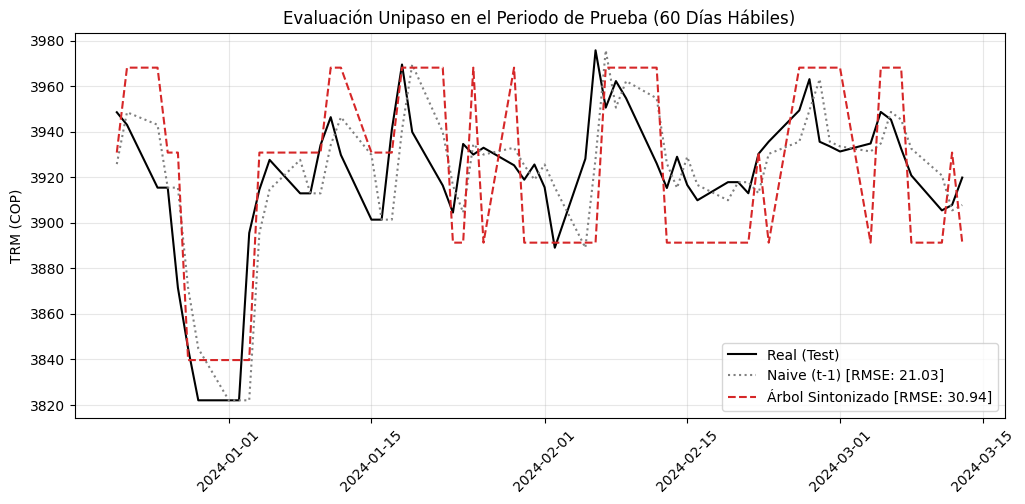

In [13]:
plt.figure(figsize=(12, 5))
plt.plot(y_test.index, y_test, label='Real (Test)', color='black', linewidth=1.5)
plt.plot(y_test.index, y_naive, label=f'Naive (t-1) [RMSE: {rmse_naive:.2f}]', linestyle=':', color='gray')
plt.plot(y_test.index, y_pred_best, label=f'Árbol Sintonizado [RMSE: {rmse_best:.2f}]', linestyle='--', color='tab:red')
plt.title('Evaluación Unipaso en el Periodo de Prueba (60 Días Hábiles)')
plt.ylabel('TRM (COP)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3);

Los coeficientes de este modelo son:

In [14]:
trm_features = pd.DataFrame({'Feature': X_train.columns, 'Coeficientes': best_model.feature_importances_})
trm_features.sort_values('Coeficientes', ascending=False).head(5)

,Feature,Coeficientes
0,TRM-1,0.818593
4,TRM-5,0.179304
15,TRM-16,0.001908
10,TRM-11,0.000062
8,TRM-9,0.000049


# Mejoras en la evaluación de modelos de pronóstico

La forma tradicional de evaluar un modelo de pronóstico, que fue la usada arriba, puede no ser realista, y puede tener desempeños inflados, porque en la vida real (en producción), los datos para predecir más allá del primer valor en la ventana de predicción no están disponibles.

Por esta razón se han desarrollado otros enfoques paa evaluar estos modelos que son más realistas. Entre estos están:

- **Predicción Recursiva**: Simular el entorno real haciendo predicciones paso a paso, alimentando al modelo con sus propias predicciones en lugar de los valores reales.
- **Walk-Forward Validation (WFV)**: similar al anterior solo que los modelos se reentrenan en cada paso.
- **Predicción Directa para un Horizonte Fijo**: Entrenar el modelo para predecir directamente varios pasos hacia el futuro (por ejemplo, los próximos 5 o 10 puntos).

Veamos un ejemplo de predicción recursiva con un horizonte de 10 días:

Punto de corte t (último dato observado): 2024-02-28
Horizonte a pronosticar (t+1 a t+10):     2024-02-29 al 2024-03-13

--- Desempeño en el Horizonte h = 10 ---
1. Unipaso (con fuga del dato real t-1): RMSE = 30.05 COP
2. Naive Persistente (repetir TRM_corte):  RMSE = 15.64 COP
3. Árbol Recursivo (despliegue real):     RMSE = 42.38 COP


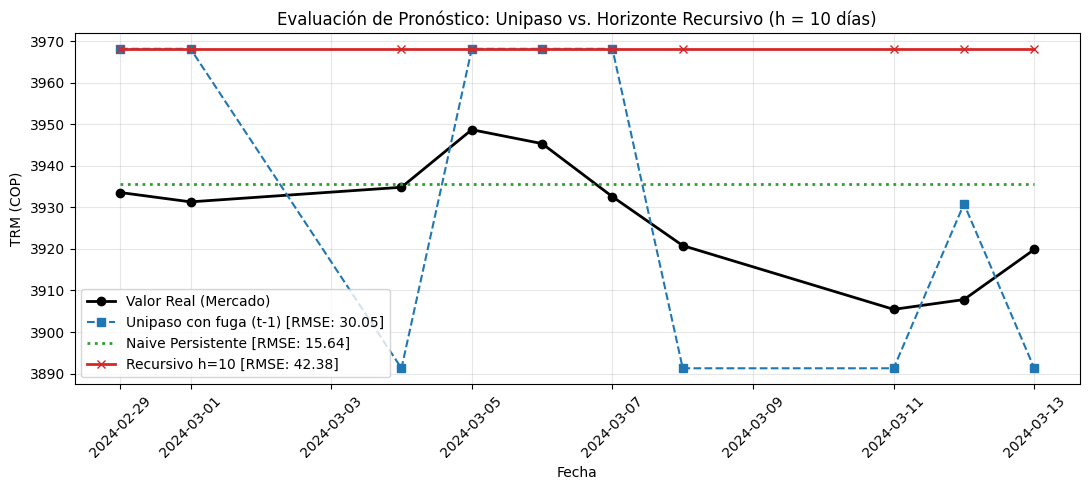

In [15]:
# 1. Definir el horizonte y la ventana de proyección (últimos 10 días hábiles del test)
h = 10
fechas_pronostico = y_test.index[-h:]
fecha_corte = y_test.index[-h - 1]

print(f"Punto de corte t (último dato observado): {fecha_corte.date()}")
print(f"Horizonte a pronosticar (t+1 a t+{h}):     {fechas_pronostico[0].date()} al {fechas_pronostico[-1].date()}")

# 2. Bucle de pronóstico recursivo (alimentación con predicciones previas)
serie_historica = trm.loc[:fecha_corte, 'TRM'].copy()
predicciones_recursivas = []

for fecha in fechas_pronostico:
    # Construcción dinámica de rezagos y media móvil a partir de la serie actualizada
    fila_actual = {}
    for i in range(1, retardo + 1):
        fila_actual[f'TRM-{i}'] = serie_historica.iloc[-i]
    
    fila_actual['rolling_7d_mean'] = serie_historica.iloc[-7:].mean()
    fila_actual['dia_semana'] = fecha.weekday()
    fila_actual['mes'] = fecha.month
    fila_actual['año'] = fecha.year
    
    # Asegurar el orden de columnas del conjunto de entrenamiento
    x_input = pd.DataFrame([fila_actual], index=[fecha])[X_train.columns]
    
    # Inferencia y realimentación a la serie histórica
    y_hat_t = best_model.predict(x_input)[0]
    predicciones_recursivas.append(y_hat_t)
    serie_historica.loc[fecha] = y_hat_t

y_rec = pd.Series(predicciones_recursivas, index=fechas_pronostico)

# 3. Líneas base de comparación para el mismo periodo de 10 días
y_real_h10 = y_test.loc[fechas_pronostico]
# Naive persistente a horizonte h: proyectar el último valor observado en el corte
y_naive_h10 = pd.Series(trm.loc[fecha_corte, 'TRM'], index=fechas_pronostico)
# Unipaso: predicción estándar con fuga del dato real t-1
y_onestep_h10 = best_model.predict(X_test.loc[fechas_pronostico])

# 4. Cálculo de métricas
rmse_onestep = root_mean_squared_error(y_real_h10, y_onestep_h10)
rmse_naive   = root_mean_squared_error(y_real_h10, y_naive_h10)
rmse_rec     = root_mean_squared_error(y_real_h10, y_rec)

print("\n--- Desempeño en el Horizonte h = 10 ---")
print(f"1. Unipaso (con fuga del dato real t-1): RMSE = {rmse_onestep:.2f} COP")
print(f"2. Naive Persistente (repetir TRM_corte):  RMSE = {rmse_naive:.2f} COP")
print(f"3. Árbol Recursivo (despliegue real):     RMSE = {rmse_rec:.2f} COP")

# 5. Visualización del contraste metodológico
plt.figure(figsize=(11, 5))
plt.plot(fechas_pronostico, y_real_h10.values, label='Valor Real (Mercado)', color='black', marker='o', linewidth=2)
plt.plot(fechas_pronostico, y_onestep_h10, label=f'Unipaso con fuga (t-1) [RMSE: {rmse_onestep:.2f}]', linestyle='--', color='tab:blue', marker='s')
plt.plot(fechas_pronostico, y_naive_h10.values, label=f'Naive Persistente [RMSE: {rmse_naive:.2f}]', linestyle=':', color='tab:green', linewidth=2)
plt.plot(fechas_pronostico, y_rec.values, label=f'Recursivo h=10 [RMSE: {rmse_rec:.2f}]', color='tab:red', marker='x', linewidth=2)

plt.title('Evaluación de Pronóstico: Unipaso vs. Horizonte Recursivo (h = 10 días)')
plt.ylabel('TRM (COP)')
plt.xlabel('Fecha')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show();

## Conclusiones: Lecciones Críticas del Pronóstico Tabular con Machine Learning

A partir de la comparación empírica realizada entre la evaluación unipaso, la predicción recursiva y la línea base ingenua (*Naive*), se desprenden tres lecciones metodológicas fundamentales:

1. **La ilusión de la evaluación unipaso (*One-step-ahead Leakage*):**  
   Evaluar un modelo de pronóstico simplemente aplicando `model.predict(X_test)` de forma vectorial genera una falsa sensación de precisión. En cada punto $t+k$, el modelo está recibiendo como entrada el valor real observado del día anterior ($y_{t+k-1}$). En un entorno de producción con horizonte de planeación a varios días ($h > 1$), esos valores futuros no existen. Al obligar al modelo a pronosticar de forma recursiva realimentándose con sus propias estimaciones, el error se incrementa sustancialmente.

2. **La limitación estructural de los árboles en horizontes recursivos:**  
   Los modelos basados en particionamiento recursivo (CART, Random Forest, GBDT) dividen el espacio en regiones ortogonales y asignan el promedio de la hoja como predicción. Al encadenar predicciones consecutivas, los rezagos estimados caen rápidamente y de forma determinista en la misma partición terminal, provocando que el pronóstico colapse en una asíntota plana constante. Además, estos algoritmos carecen por diseño de la capacidad de extrapolar tendencias más allá del rango de valores visto en entrenamiento.

3. **La persistencia como punto de referencia (*Benchmark Naive*):**  
   En series financieras con alta persistencia y comportamiento cercano a un paseo aleatorio (como la TRM), el valor de ayer suele ser el predictor más robusto del valor de hoy ($y_t \approx y_{t-1} + \epsilon_t$). Complejizar el problema con algoritmos tabulares sobre los niveles de la serie rara vez supera a una simple proyección del último valor conocido. Para que los modelos de aprendizaje supervisado aporten valor predictivo real en estas series, el problema debe reformularse modelando **retornos o primeras diferencias** ($\Delta y_t$) e incorporando variables macroeconómicas exógenas con verdadero poder causal.

Los modelos lineales pueden funcioanr mejor:

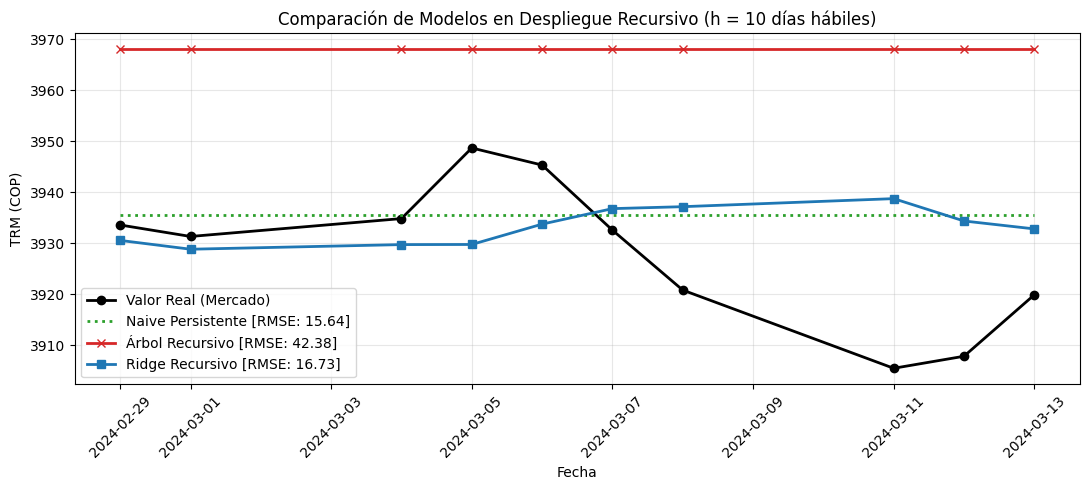

In [16]:
import numpy as np
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# 1. Definir horizonte y fechas de pronóstico (últimos 10 días hábiles de prueba)
h = 10
fechas_pronostico = y_test.index[-h:]
fecha_corte = y_test.index[-h - 1]
y_real_h10 = y_test.loc[fechas_pronostico]

# 2. Ajuste del modelo Ridge regularizado con estandarización
ridge_pipe = make_pipeline(
    StandardScaler(),
    RidgeCV(alphas=np.logspace(-3, 5, 50))
)
ridge_pipe.fit(X_train, y_train)

# 3. Pronóstico recursivo a h = 10 pasos para Ridge
historia_ridge = trm.loc[:fecha_corte, 'TRM'].copy()
preds_ridge_rec = []

for fecha in fechas_pronostico:
    fila = {f'TRM-{i}': historia_ridge.iloc[-i] for i in range(1, retardo + 1)}
    fila['rolling_7d_mean'] = historia_ridge.iloc[-7:].mean()
    fila['dia_semana'] = fecha.weekday()
    fila['mes'] = fecha.month
    fila['año'] = fecha.year
    
    x_in = pd.DataFrame([fila], index=[fecha])[X_train.columns]
    y_hat = ridge_pipe.predict(x_in)[0]
    preds_ridge_rec.append(y_hat)
    historia_ridge.loc[fecha] = y_hat

s_ridge_rec = pd.Series(preds_ridge_rec, index=fechas_pronostico)

# 4. Pronóstico recursivo a h = 10 pasos para el Árbol podado (best_model)
historia_tree = trm.loc[:fecha_corte, 'TRM'].copy()
preds_tree_rec = []

for fecha in fechas_pronostico:
    fila = {f'TRM-{i}': historia_tree.iloc[-i] for i in range(1, retardo + 1)}
    fila['rolling_7d_mean'] = historia_tree.iloc[-7:].mean()
    fila['dia_semana'] = fecha.weekday()
    fila['mes'] = fecha.month
    fila['año'] = fecha.year
    
    x_in = pd.DataFrame([fila], index=[fecha])[X_train.columns]
    y_hat = best_model.predict(x_in)[0]
    preds_tree_rec.append(y_hat)
    historia_tree.loc[fecha] = y_hat

s_tree_rec = pd.Series(preds_tree_rec, index=fechas_pronostico)

# 5. Línea base Naive persistente (proyectar el valor observado en la fecha de corte)
y_naive_h10 = pd.Series(trm.loc[fecha_corte, 'TRM'], index=fechas_pronostico)

# 6. Cálculo del RMSE para cada aproximación
rmse_naive = root_mean_squared_error(y_real_h10, y_naive_h10)
rmse_tree  = root_mean_squared_error(y_real_h10, s_tree_rec)
rmse_ridge = root_mean_squared_error(y_real_h10, s_ridge_rec)

# 7. Construcción de la visualización comparativa
plt.figure(figsize=(11, 5))
plt.plot(fechas_pronostico, y_real_h10.values, label='Valor Real (Mercado)', color='black', marker='o', linewidth=2)
plt.plot(fechas_pronostico, y_naive_h10.values, label=f'Naive Persistente [RMSE: {rmse_naive:.2f}]', linestyle=':', color='tab:green', linewidth=2)
plt.plot(fechas_pronostico, s_tree_rec.values, label=f'Árbol Recursivo [RMSE: {rmse_tree:.2f}]', color='tab:red', marker='x', linewidth=2)
plt.plot(fechas_pronostico, s_ridge_rec.values, label=f'Ridge Recursivo [RMSE: {rmse_ridge:.2f}]', color='tab:blue', marker='s', linewidth=2)

plt.title('Comparación de Modelos en Despliegue Recursivo (h = 10 días hábiles)')
plt.ylabel('TRM (COP)')
plt.xlabel('Fecha')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()